In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score

In [51]:
# Load dataset
url="https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df=pd.read_csv(url)

# Select required columns
df=df[['displacement','mpg']]

# Remove missing values
df=df.dropna()

df.head()

,displacement,mpg
0,307.0,18.0
1,350.0,15.0
2,318.0,18.0
3,304.0,16.0
4,302.0,17.0


In [52]:
# Select feature and target
X=df[['displacement']].values
y=df['mpg'].values

In [53]:
# Split data
X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.2,
    random_state=42
)

In [54]:
# Linear Regression
linear_model=LinearRegression()
linear_model.fit(X_train,y_train)

y_pred_linear=linear_model.predict(X_test)

mse_linear=mean_squared_error(y_test,y_pred_linear)
r2_linear=r2_score(y_test,y_pred_linear)

print("Linear Regression")
print("-----------------")
print("MSE:",mse_linear)
print("R2 score:",r2_linear)

Linear Regression
-----------------
MSE: 18.102543998358946
R2 score: 0.6633114869465596


In [55]:
results=[]
polynomial_models={}

results.append({
    'Model':'Linear Regression',
    'Degree':1,
    'MSE':mse_linear,
    'R-squared':r2_linear
})

for degree in range(2,6):

    poly=PolynomialFeatures(degree=degree)

    X_train_poly=poly.fit_transform(X_train)
    X_test_poly=poly.transform(X_test)

    poly_model=LinearRegression()
    poly_model.fit(X_train_poly,y_train)

    y_pred_poly=poly_model.predict(X_test_poly)

    mse=mean_squared_error(y_test,y_pred_poly)
    r2=r2_score(y_test,y_pred_poly)

    results.append({
        'Model':'Polynomial Regression',
        'Degree':degree,
        'MSE':mse,
        'R-squared':r2
    })

    polynomial_models[degree]=(poly,poly_model)

In [56]:
results_df=pd.DataFrame(results)
print(results_df)

                   Model  Degree        MSE  R-squared
0      Linear Regression       1  18.102544   0.663311
1  Polynomial Regression       2  15.107354   0.719019
2  Polynomial Regression       3  16.369649   0.695542
3  Polynomial Regression       4  18.398790   0.657802
4  Polynomial Regression       5  20.998146   0.609456


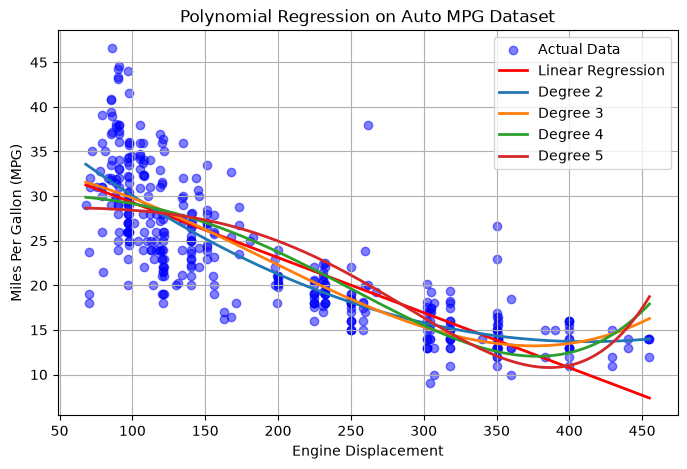

In [57]:
x_range=np.linspace(X.min(),X.max(),300).reshape(-1,1)

plt.figure(figsize=(8,5))

plt.scatter(X,y,color='blue',alpha=0.5,label='Actual Data')

index=np.argsort(x_range.flatten())

plt.plot(
    x_range.flatten()[index],
    linear_model.predict(x_range)[index],
    color='red',
    linewidth=2,
    label='Linear Regression'
)

for degree,(poly,model) in polynomial_models.items():

    plt.plot(
        x_range.flatten()[index],
        model.predict(poly.transform(x_range))[index],
        linewidth=2,
        label=f'Degree {degree}'
    )

plt.title("Polynomial Regression on Auto MPG Dataset")
plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.legend()
plt.grid(True)
plt.show()

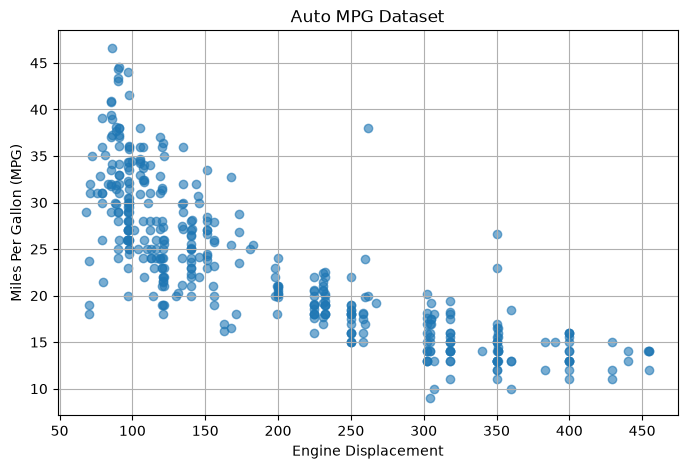

In [58]:
# Scatter Plot
plt.figure(figsize=(8,5))
plt.scatter(X, y, alpha=0.6)
plt.xlabel('Engine Displacement')
plt.ylabel('Miles Per Gallon (MPG)')
plt.title('Auto MPG Dataset')
plt.grid(True)
plt.show()


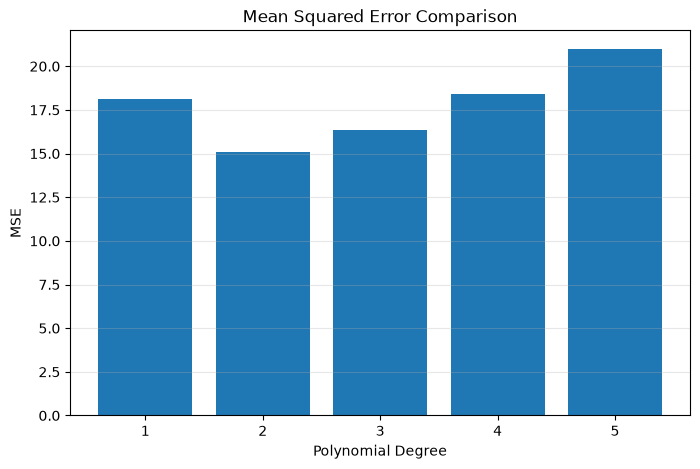

In [59]:
# MSE Comparison Graph
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.bar(results_df['Degree'].astype(str), results_df['MSE'])
plt.title('Mean Squared Error Comparison')
plt.xlabel('Polynomial Degree')
plt.ylabel('MSE')
plt.grid(axis='y', alpha=0.3)
plt.show()


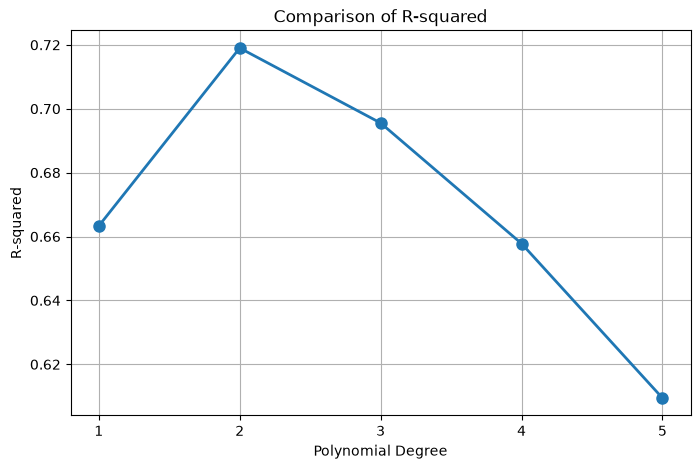

In [60]:
# R² Comparison Graph
plt.figure(figsize=(8,5))

plt.plot(
    results_df['Degree'],
    results_df['R-squared'],
    marker='o',
    linewidth=2,
    markersize=8
)

plt.title("Comparison of R-squared")
plt.xlabel("Polynomial Degree")
plt.ylabel("R-squared")

plt.xticks(results_df['Degree'])
plt.grid(True)

plt.show()